In [2]:
from google.colab import files

uploaded = files.upload()

Saving breast_cancer.csv to breast_cancer.csv


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("All libraries imported successfully!")

Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
All libraries imported successfully!


In [3]:
df = pd.read_csv("breast_cancer.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


In [4]:
print(df["diagnosis"].value_counts())

diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


In [5]:
print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Records:", df.duplicated().sum())

Missing Values: 0
Duplicate Records: 0


In [6]:
X = df.drop("diagnosis", axis=1)

y = df["diagnosis"].map({
    "Malignant": 1,
    "Benign": 0
})

print("Features:", X.shape)
print("Target:", y.shape)

Features: (569, 30)
Target: (569,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [9]:
import os

os.makedirs("outputs", exist_ok=True)

print("Output folder created!")

Output folder created!


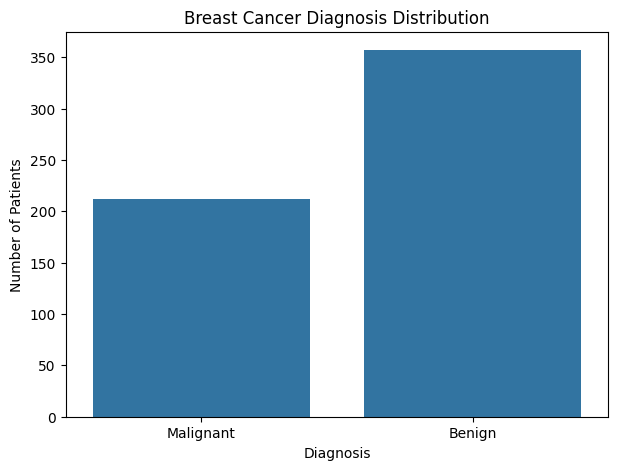

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="diagnosis")

plt.title("Breast Cancer Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")

plt.savefig("outputs/class_distribution.png")
plt.show()

In [14]:
print(df.columns.tolist())

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'diagnosis']


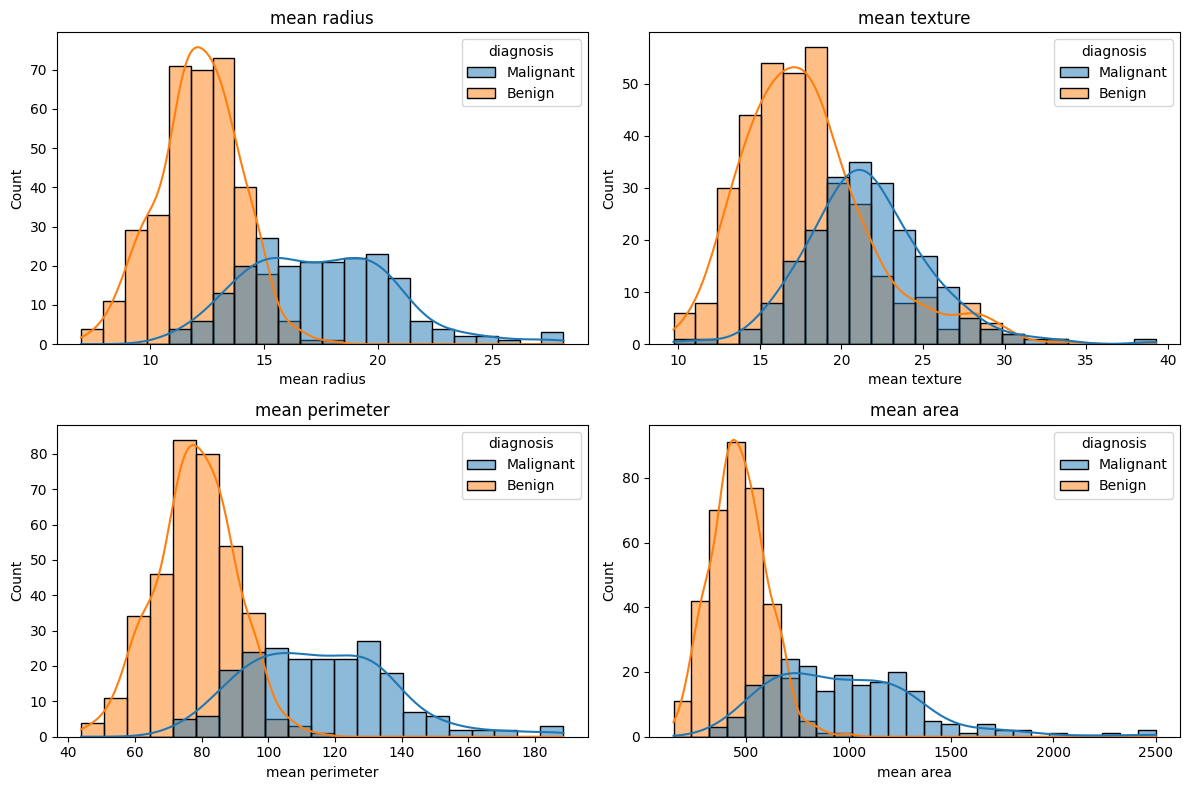

In [15]:
features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

plt.figure(figsize=(12, 8))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)

    sns.histplot(
        data=df,
        x=feature,
        hue="diagnosis",
        kde=True
    )

    plt.title(feature)

plt.tight_layout()
plt.savefig("outputs/feature_distributions.png")
plt.show()

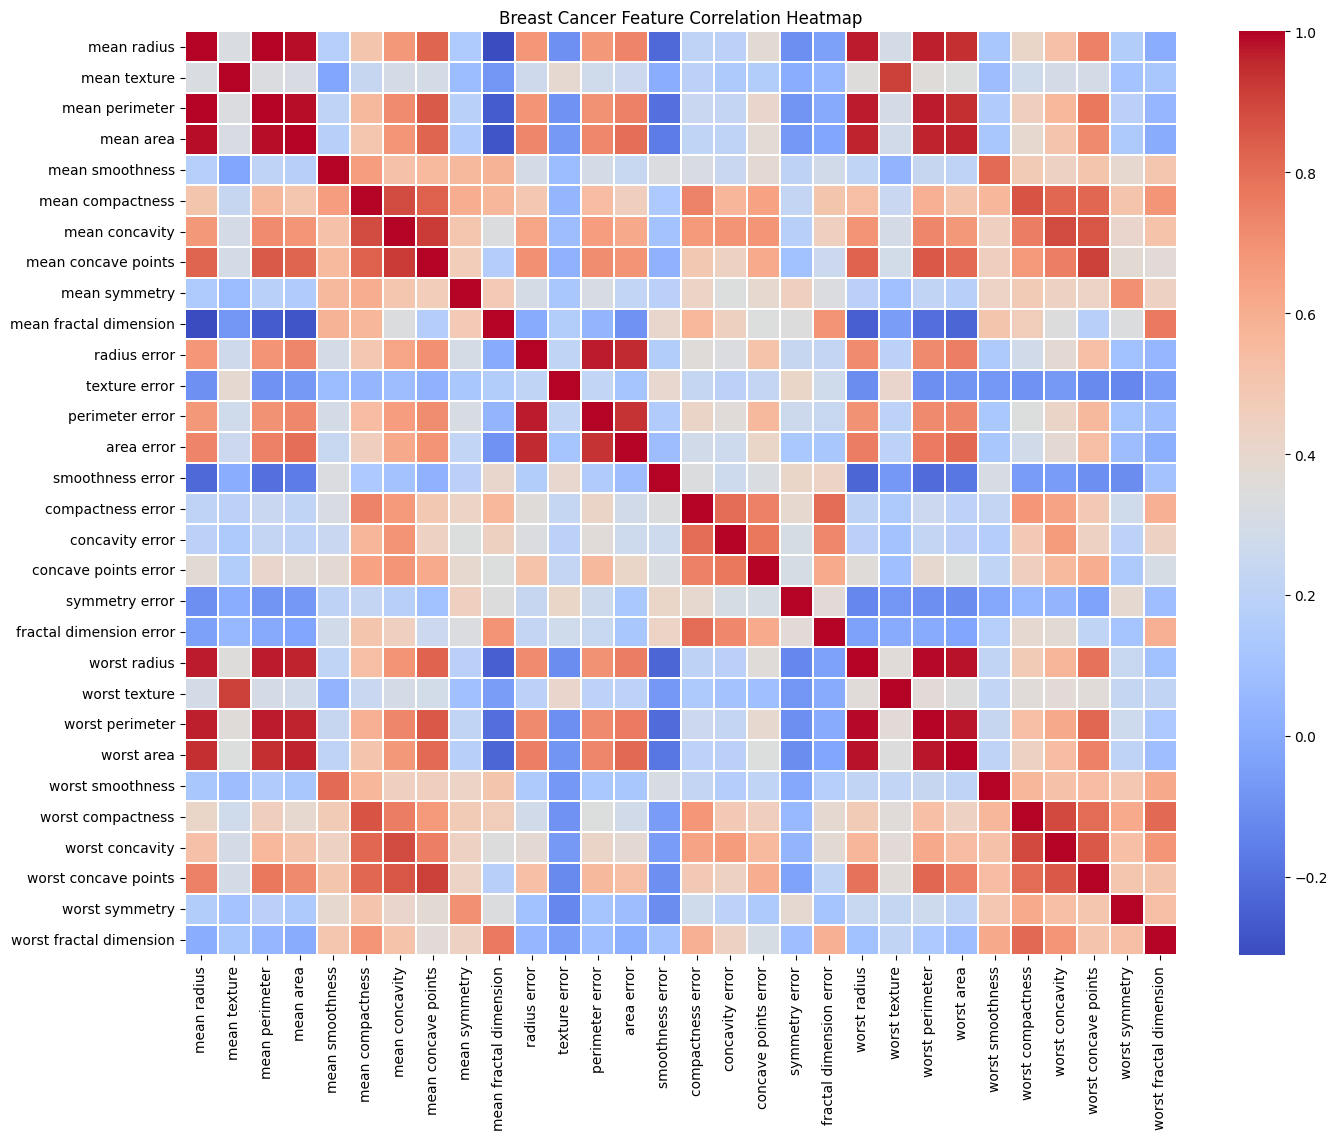

In [12]:
plt.figure(figsize=(16, 12))

correlation = df.drop(
    columns=["diagnosis"]
).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Breast Cancer Feature Correlation Heatmap")

plt.savefig("outputs/correlation_heatmap.png")
plt.show()

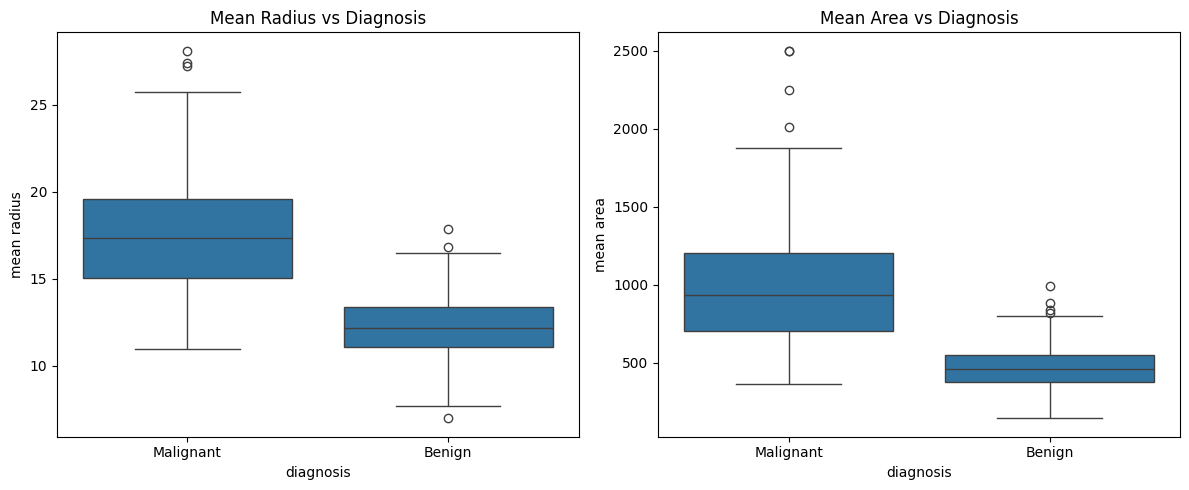

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x="diagnosis", y="mean radius")
plt.title("Mean Radius vs Diagnosis")

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x="diagnosis", y="mean area")
plt.title("Mean Area vs Diagnosis")

plt.tight_layout()

plt.savefig("outputs/feature_comparison.png")
plt.show()

In [17]:
print("Average feature values by diagnosis:")

print(
    df.groupby("diagnosis")[
        ["mean radius", "mean texture",
         "mean perimeter", "mean area"]
    ].mean().round(2)
)

Average feature values by diagnosis:
           mean radius  mean texture  mean perimeter  mean area
diagnosis                                                      
Benign           12.15         17.91           78.08     462.79
Malignant        17.46         21.60          115.37     978.38


### Feature Distribution Analysis

The histograms compare four important features across malignant and benign breast cancer samples.

**Observations:**
- Malignant samples generally have higher mean radius values.
- Mean perimeter is higher in malignant samples.
- Mean area shows a clear difference between the two diagnosis classes.
- Mean texture distributions overlap, indicating that this feature alone may not clearly separate both classes.

**Conclusion:**

Mean radius, mean perimeter and mean area appear to be useful predictive features. Multiple features should be considered together when developing the classification models.

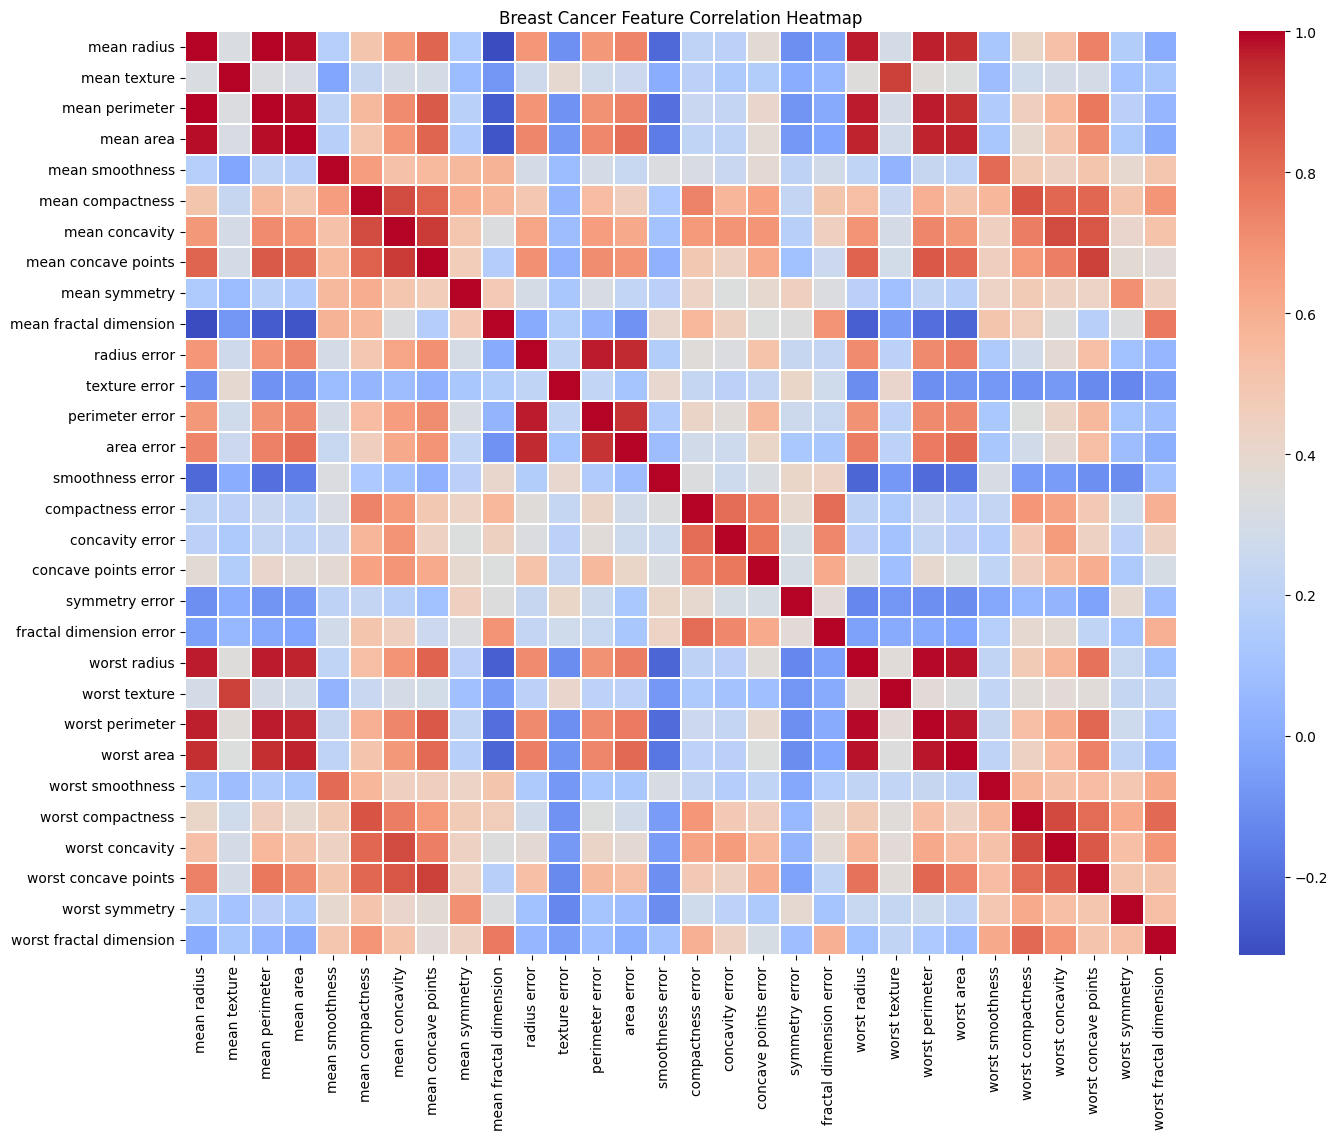

In [18]:
plt.figure(figsize=(16, 12))

correlation = df.drop(
    columns=["diagnosis"]
).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Breast Cancer Feature Correlation Heatmap")

plt.savefig(
    "outputs/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Correlation Heatmap Analysis

The correlation heatmap illustrates relationships between the 30 numerical features of the Wisconsin Breast Cancer dataset.

**Key observations:**

1. Mean radius, mean perimeter and mean area exhibit strong positive correlations.
2. Worst radius, worst perimeter and worst area also show strong positive relationships.
3. Compactness, concavity and concave points demonstrate noticeable positive correlations.
4. Highly correlated features may contain overlapping information.

**Conclusion:**

The dataset contains several correlated features. Feature scaling and comparison of different machine learning algorithms will help determine suitable predictive models.

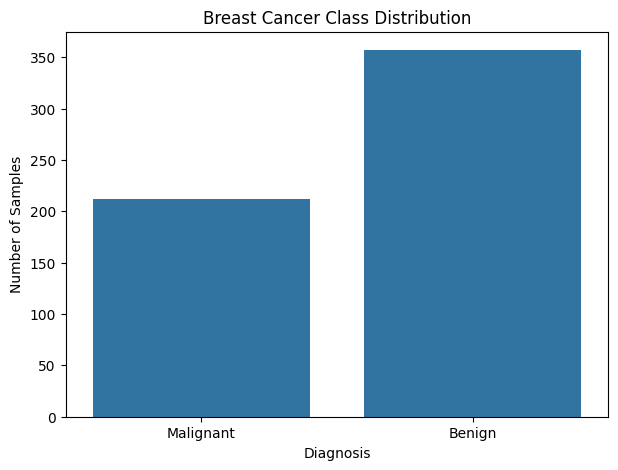

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="diagnosis")

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

plt.savefig(
    "outputs/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("ML libraries imported successfully!")

ML libraries imported successfully!


In [21]:
# Logistic Regression Model

lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [22]:
# Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [23]:
# SVM Model

svm_model = SVC(
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_predictions = svm_model.predict(X_test_scaled)

print("SVM trained successfully!")

SVM trained successfully!


In [24]:
# Model Evaluation

models = {
    "Logistic Regression": (
        lr_model, X_test_scaled
    ),
    "Random Forest": (
        rf_model, X_test
    ),
    "SVM": (
        svm_model, X_test_scaled
    )
}

results = []

for name, (model, test_data) in models.items():

    predictions = model.predict(test_data)

    probabilities = model.predict_proba(test_data)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  AUC-ROC
0  Logistic Regression    0.9649     0.9750  0.9286    0.9512   0.9960
1        Random Forest    0.9737     1.0000  0.9286    0.9630   0.9965
2                  SVM    0.9825     0.9762  0.9762    0.9762   0.9954


<Figure size 1000x600 with 0 Axes>

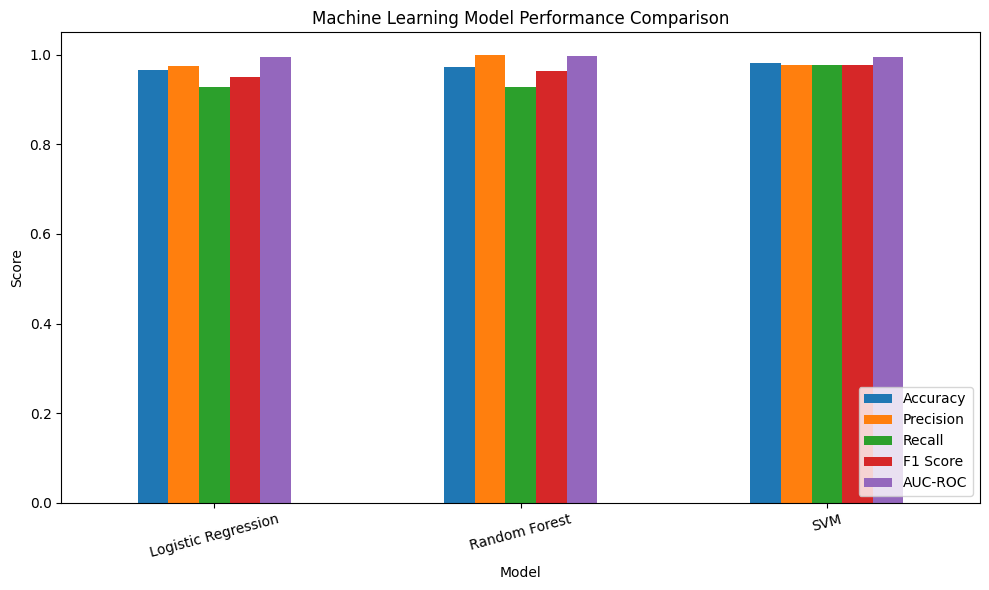

In [25]:
plt.figure(figsize=(10, 6))

results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

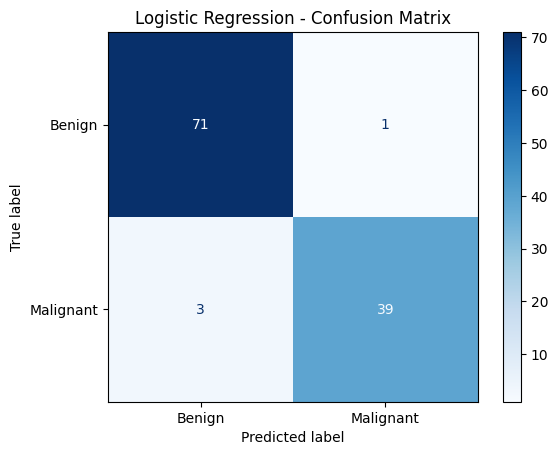

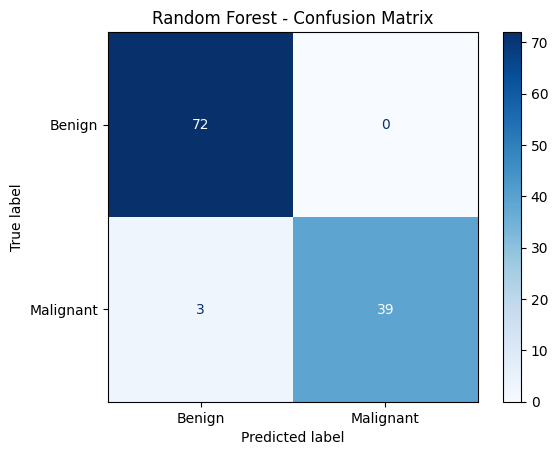

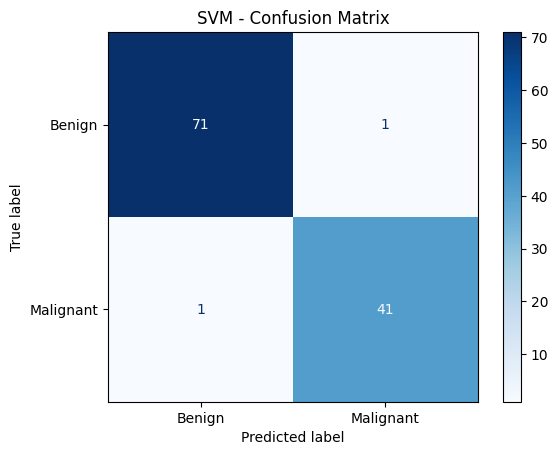

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, (model, test_data) in models.items():

    predictions = model.predict(test_data)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Benign", "Malignant"],
        cmap="Blues"
    )

    plt.title(name + " - Confusion Matrix")
    plt.show()

In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

print("Hyperparameter tuning libraries imported!")

Hyperparameter tuning libraries imported!


In [28]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = "recall"

print("5-Fold Stratified Cross Validation ready!")

5-Fold Stratified Cross Validation ready!


In [29]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

lr_params = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best Parameters:", lr_grid.best_params_)
print("Best CV Recall:", lr_grid.best_score_)

Best Parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best CV Recall: 0.9588235294117646


In [30]:
rf_model_tuning = RandomForestClassifier(
    random_state=42
)

rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"]
}

rf_grid = GridSearchCV(
    rf_model_tuning,
    rf_params,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Parameters:", rf_grid.best_params_)
print("Best CV Recall:", rf_grid.best_score_)

Best Parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV Recall: 0.9529411764705882


In [31]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

svm_params = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1],
    "model__kernel": ["rbf"],
    "model__class_weight": [None, "balanced"]
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best Parameters:", svm_grid.best_params_)
print("Best CV Recall:", svm_grid.best_score_)

Best Parameters: {'model__C': 10, 'model__class_weight': None, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV Recall: 0.9647058823529411


In [32]:
tuned_models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "SVM": svm_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "AUC-ROC": roc_auc_score(y_test, probabilities)
    })

tuned_results_df = pd.DataFrame(tuned_results)

print(tuned_results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  AUC-ROC
0  Logistic Regression    0.9737     0.9756  0.9524    0.9639   0.9954
1        Random Forest    0.9737     1.0000  0.9286    0.9630   0.9967
2                  SVM    0.9737     1.0000  0.9286    0.9630   0.9927


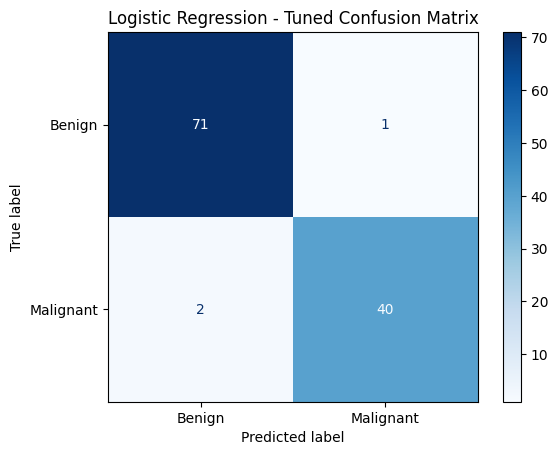

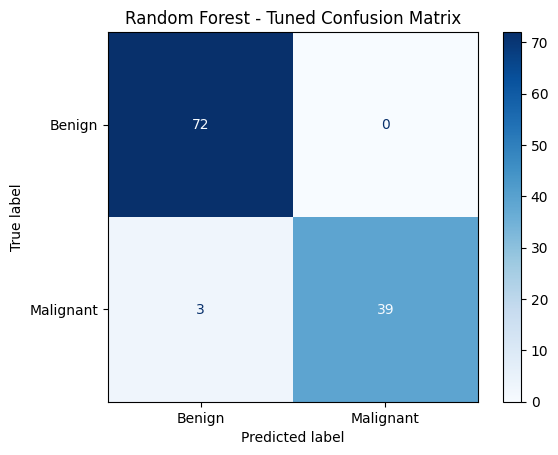

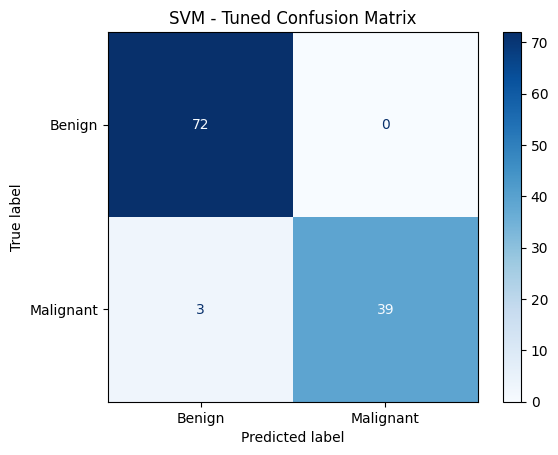

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in tuned_models.items():

    predictions = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Benign", "Malignant"],
        cmap="Blues"
    )

    plt.title(name + " - Tuned Confusion Matrix")
    plt.show()


In [34]:
for name, model in tuned_models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    predictions = model.predict(X_test)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Benign", "Malignant"]
        )
    )


Logistic Regression
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


Random Forest
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


SVM
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97

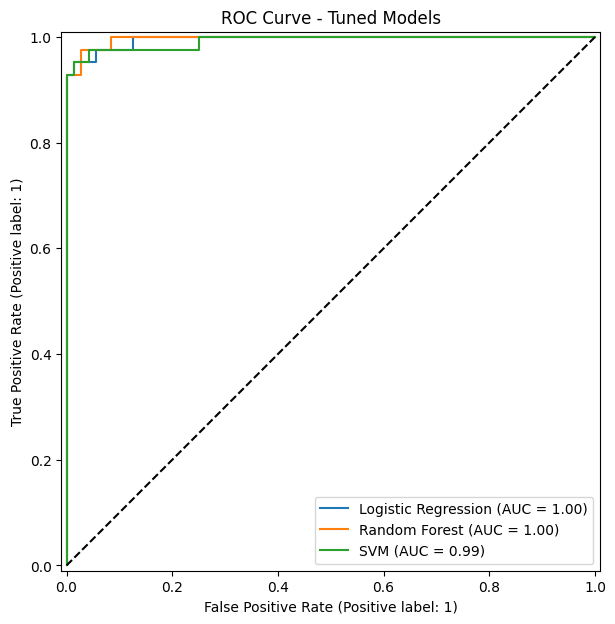

In [35]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 7))

for name, model in tuned_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], "k--")

plt.title("ROC Curve - Tuned Models")
plt.savefig(
    "outputs/tuned_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
comparison = pd.concat(
    [
        results_df.assign(Stage="Before Tuning"),
        tuned_results_df.assign(Stage="After Tuning")
    ],
    ignore_index=True
)

print(
    comparison[
        ["Model", "Stage", "Accuracy",
         "Precision", "Recall", "F1 Score", "AUC-ROC"]
    ].round(4)
)

                 Model          Stage  Accuracy  Precision  Recall  F1 Score  \
0  Logistic Regression  Before Tuning    0.9649     0.9750  0.9286    0.9512   
1        Random Forest  Before Tuning    0.9737     1.0000  0.9286    0.9630   
2                  SVM  Before Tuning    0.9825     0.9762  0.9762    0.9762   
3  Logistic Regression   After Tuning    0.9737     0.9756  0.9524    0.9639   
4        Random Forest   After Tuning    0.9737     1.0000  0.9286    0.9630   
5                  SVM   After Tuning    0.9737     1.0000  0.9286    0.9630   

   AUC-ROC  
0   0.9960  
1   0.9965  
2   0.9954  
3   0.9954  
4   0.9967  
5   0.9927  


In [37]:
print("FINAL TUNED MODEL COMPARISON")

display(
    tuned_results_df.sort_values(
        by=["Recall", "AUC-ROC", "F1 Score"],
        ascending=False
    ).round(4)
)

FINAL TUNED MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9954
1,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9967
2,SVM,0.9737,1.0000,0.9286,0.9630,0.9927


In [38]:
for name, model in tuned_models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    tn, fp, fn, tp = cm.ravel()

    print("\nModel:", name)
    print("False Negatives:", fn)
    print("True Positives:", tp)
    print("False Positives:", fp)
    print("True Negatives:", tn)


Model: Logistic Regression
False Negatives: 2
True Positives: 40
False Positives: 1
True Negatives: 71

Model: Random Forest
False Negatives: 3
True Positives: 39
False Positives: 0
True Negatives: 72

Model: SVM
False Negatives: 3
True Positives: 39
False Positives: 0
True Negatives: 72


### Best Model Selection and Justification

Three machine learning algorithms were evaluated: Logistic Regression, Random Forest and Support Vector Machine (SVM).

All three models achieved an accuracy of 97.37%.

Logistic Regression achieved the highest malignant-class recall of 95.24%, an F1-score of 96.39%, and an AUC-ROC of 99.54%. It also produced only two false-negative predictions.

Random Forest achieved the highest AUC-ROC of 99.67%, while SVM achieved 99.27%.

**Final Model: Logistic Regression**

Logistic Regression was selected as the primary model because it demonstrated the highest malignant-class recall and F1-score while producing the fewest false negatives.

It provides the preferred balance for this project's priority of identifying malignant cases.

In [39]:
import os
import joblib

os.makedirs("models", exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [40]:
# Select the tuned Logistic Regression pipeline

best_model = lr_grid.best_estimator_

# Create a model bundle

model_bundle = {
    "model": best_model,
    "feature_names": X.columns.tolist(),
    "target_mapping": {
        "Malignant": 1,
        "Benign": 0
    },
    "model_name": "Logistic Regression"
}

# Save model and metadata together

joblib.dump(
    model_bundle,
    "models/best_breast_cancer_model.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!


In [41]:
# Load the saved model

loaded_bundle = joblib.load(
    "models/best_breast_cancer_model.joblib"
)

loaded_model = loaded_bundle["model"]

# Make predictions using the original test features

saved_predictions = loaded_model.predict(X_test)

print("Saved model:", loaded_bundle["model_name"])
print("Predictions:", saved_predictions[:10])

print("Model loaded and verified successfully!")

Saved model: Logistic Regression
Predictions: [0 1 0 1 1 0 1 0 0 0]
Model loaded and verified successfully!


In [42]:
print(
    "Accuracy:",
    accuracy_score(y_test, saved_predictions)
)

print(
    "Malignant Recall:",
    recall_score(y_test, saved_predictions)
)

print(
    "Confusion Matrix:\n",
    confusion_matrix(y_test, saved_predictions)
)

Accuracy: 0.9736842105263158
Malignant Recall: 0.9523809523809523
Confusion Matrix:
 [[71  1]
 [ 2 40]]


In [43]:
from google.colab import files

files.download(
    "models/best_breast_cancer_model.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
!pip install shap

In [45]:
import shap
import matplotlib.pyplot as plt
import pandas as pd

print("SHAP imported successfully!")

SHAP imported successfully!


In [46]:
best_model = loaded_bundle["model"]

# Extract Logistic Regression classifier
lr_classifier = best_model.named_steps["model"]

# Extract StandardScaler
scaler = best_model.named_steps["scaler"]

print("Model and scaler extracted successfully!")

Model and scaler extracted successfully!


In [47]:
# Transform test data using the trained scaler
X_test_transformed = scaler.transform(X_test)

# Convert to DataFrame for feature names
X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=X.columns
)

# Create SHAP Linear Explainer
explainer = shap.LinearExplainer(
    lr_classifier,
    scaler.transform(X_train)
)

shap_values = explainer(X_test_transformed)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


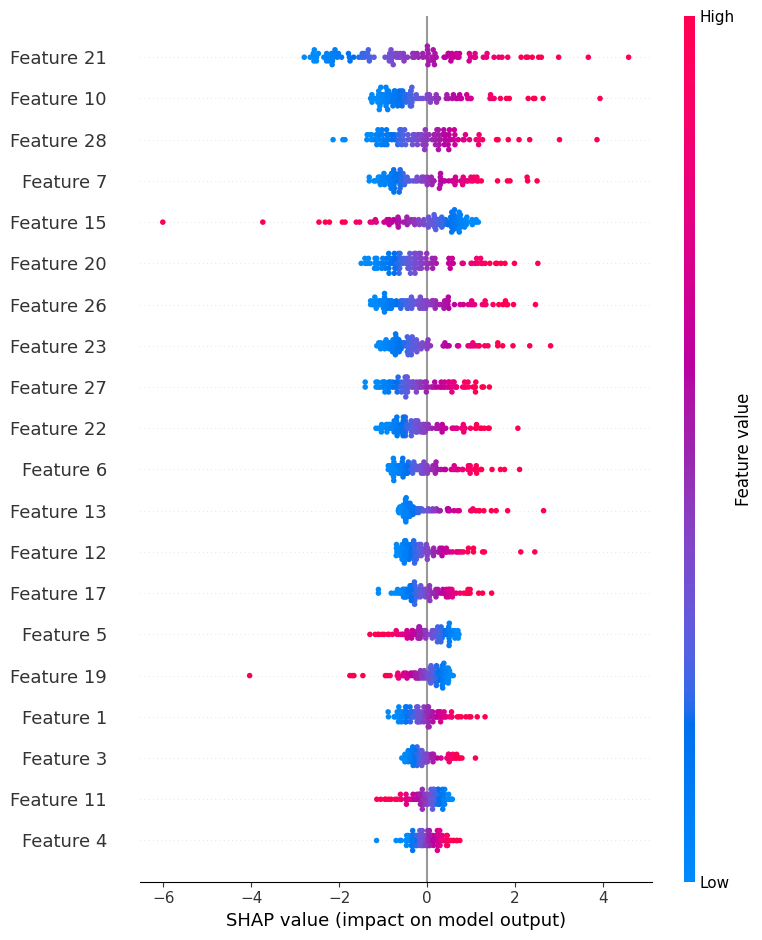

In [48]:
shap.summary_plot(
    shap_values,
    X_test_shap,
    show=True
)

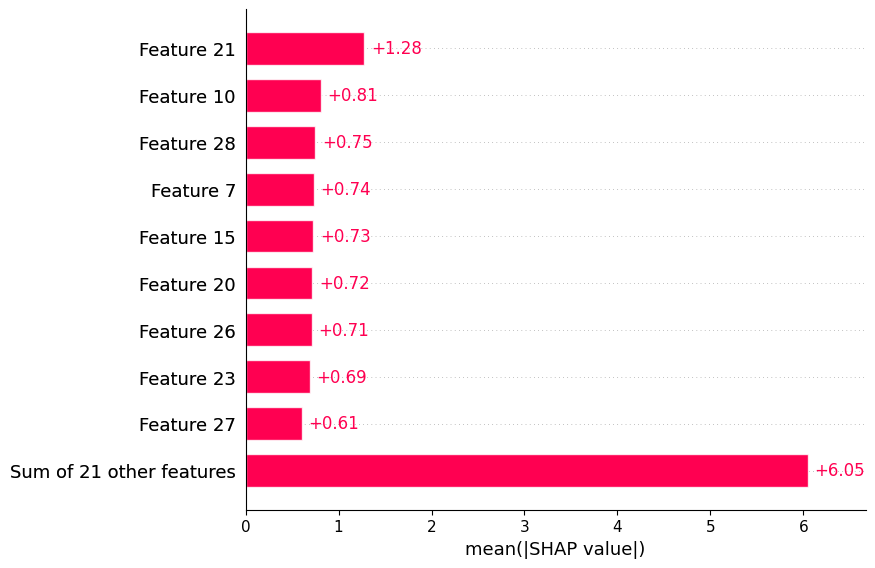

In [49]:
shap.plots.bar(shap_values)

In [50]:
plt.savefig(
    "outputs/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>